Business Understanding
        ↓
Data Collection
        ↓
Dataset Understanding
        ↓
Data Cleaning (Remove corrupted images)
        ↓
Train / Validation / Test Split
        ↓
Image Transformations
        ↓
Create Dataset (ImageFolder)
        ↓
Create DataLoaders
        ↓
Visualize Images
        ↓
Design CNN Architecture
        ↓
Choose Loss Function
        ↓
Choose Optimizer
        ↓
Training Loop
        ↓
Validation
        ↓
Hyperparameter Tuning (Optional)
        ↓
Model Evaluation
        ↓
Save Trained Model
        ↓
Inference / Prediction
        ↓
Deployment (Streamlit)
        ↓
GitHub + README

# imports

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import os

import json
import time
import copy
import shutil
import numpy as np
import matplotlib.pyplot as plt

In [5]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch Version: 2.11.0+cu130
CUDA Available: True
Using Device: cuda
GPU: Tesla T4


2. Data Collection

In [6]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'Shipsense', '"I am restarting my study journey after a 6.5-yea....gsheet', 'Google AI Studio', 'chest_xray_model_bht.pth', 'chest_xray_checkpoint_bht.pth', 'class_to_idx_bht.json', 'chest_xray_model_best.pth', 'new_chest_xray_model_bht.pth', 'new_chest_xray_checkpoint_bht.pth', 'new_class_to_idx_bht.json', 'Indian Food Images', 'indian_food_model_baseline.pth', 'indian_food_checkpoint_baseline.pth', 'indian_food_class_to_idx.json', 'Indian_Food_EfficientNet', 'kiaraadvanikapa.gdoc', 'face recogination']


In [8]:
!pip install -q kagglehub

In [9]:
import kagglehub

path = kagglehub.dataset_download("msambare/fer2013")
path

Using Colab cache for faster access to the 'fer2013' dataset.


'/kaggle/input/fer2013'

In [10]:
import os

print(os.listdir(path))

['test', 'train']


In [ ]:
#count images

for folder in ["train", "test"]:
    folder_path = os.path.join(path, folder)

    if os.path.exists(folder_path):
        print(f"\n{folder.upper()}")

        for emotion in os.listdir(folder_path):
            emotion_path = os.path.join(folder_path, emotion)

            if os.path.isdir(emotion_path):
                print(emotion, ":", len(os.listdir(emotion_path)))

3. Dataset Understanding

We will inspect:

- Number of images in each class
- Total number of images
- Image dimensions
- Image channels
- File formats
- Sample images
- Class distribution

In [12]:
#lets first clarify all paths here

train_path = os.path.join(path, "train")
test_path = os.path.join(path, "test")

In [13]:
print(os.listdir(train_path))
print(os.listdir(test_path))
print(os.listdir(path))

['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']
['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']
['test', 'train']


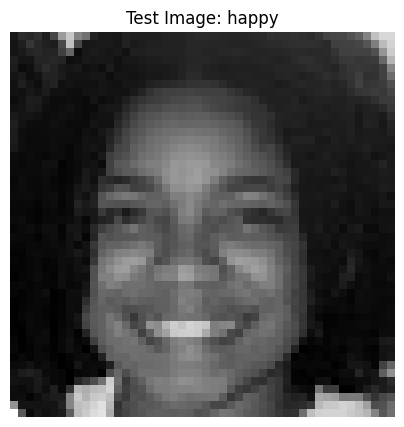

In [14]:
from PIL import Image

cls = "happy"
cls_path = os.path.join(test_path, cls)

files = os.listdir(cls_path)
sample_file = files[0]
img = Image.open(os.path.join(cls_path, sample_file))


plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.title(f"Test Image: {cls}")
plt.axis("off")
plt.show()

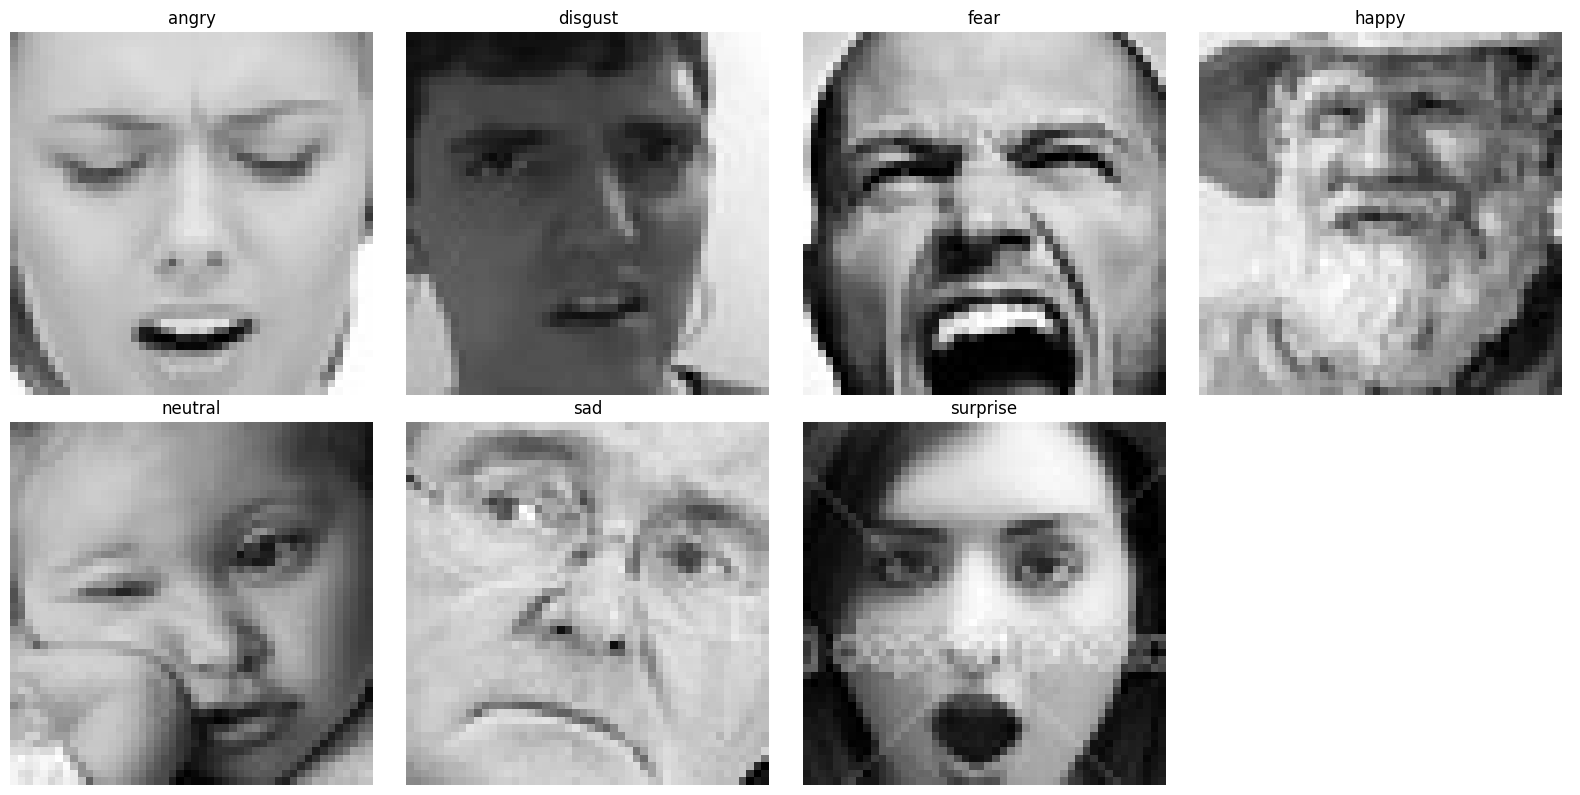

In [15]:
classes = sorted(os.listdir(train_path))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, cls in zip(axes.flatten(), classes):

    cls_path = os.path.join(train_path, cls)

    files = os.listdir(cls_path)

    if len(files) == 0:
        ax.set_title(f"{cls} (Empty)")
        ax.axis("off")
        continue

    sample_file = files[0]

    img = Image.open(os.path.join(cls_path, sample_file))

    ax.imshow(img, cmap="gray")
    ax.set_title(cls, fontsize=12)
    ax.axis("off")

# Hide unused subplot
for ax in axes.flatten()[len(classes):]:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/final_visualizing_sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# data clean


In [ ]:
#scan for curropted imag

from PIL import Image, UnidentifiedImageError
corrupted_files = []

for split in ["train", "test"]:

    split_path = os.path.join(path, split)

    for cls in os.listdir(split_path):

        cls_path = os.path.join(split_path, cls)

        for fname in os.listdir(cls_path):

            fpath = os.path.join(cls_path, fname)

            try:
                with Image.open(fpath) as img:
                    img.verify()

            except (UnidentifiedImageError, OSError, SyntaxError):
                corrupted_files.append(fpath)

print("Corrupted images found:", len(corrupted_files))
print(corrupted_files)

In [ ]:
#remove curropted image from files

#remove corrupted images

for fpath in corrupted_files:
    os.remove(fpath)

print("Removed", len(corrupted_files), "corrupted images")

#train / validation / test split and Image Transformation

Split ratio: 70% Train, 15% Validation, 15% Test.
Split is done on indices of the full ImageFolder dataset (random, seeded for reproducibility).

In [16]:
#our dataset is aready splited into train and test so we dont need to perform train test split from scratch the only thing we have to do is : create a validation folder


# Take Train folder make 20% of its as validation folder


# Step 1 — Load the training dataset

from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()])








#now transform




full_train_dataset = datasets.ImageFolder(
    root=train_path,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_path,
    transform=transform
)

print("Training images:", len(full_train_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", full_train_dataset.classes)




Training images: 28709
Testing images: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [17]:
# Step 2 — Split training data into train and validation

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Get all image indices and their corresponding labels
indices = np.arange(len(full_train_dataset))
labels = full_train_dataset.targets





#split into 80% training and 20% validation

train_indices, val_indices = train_test_split(indices,test_size=0.2,random_state=42,stratify=labels)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 22967
Validation images: 5742
Testing images: 7178


In [18]:
#lets first clarify all paths here

train_path = os.path.join(path, "train")
test_path = os.path.join(path, "test")
validation_path = os.path.join(path,"validation")

# Create DataLoaders

In [19]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

In [20]:
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Train batches: 359
Validation batches: 90
Test batches: 113
Image batch shape: torch.Size([64, 1, 48, 48])
Label batch shape: torch.Size([64])


In [21]:
labels

tensor([0, 4, 6, 3, 6, 5, 3, 4, 5, 5, 3, 6, 3, 5, 3, 5, 4, 6, 6, 6, 4, 2, 4, 3,
        0, 1, 6, 6, 3, 4, 2, 2, 4, 3, 6, 3, 0, 5, 5, 0, 3, 2, 3, 5, 3, 4, 0, 2,
        5, 2, 3, 0, 4, 2, 5, 5, 2, 3, 6, 4, 3, 4, 5, 5])

In [22]:
# CNN architecture (input: 1x48x48 grayscale)
# 48 -> pool -> 24 -> pool -> 12 -> pool -> 6 -> pool -> 3  =>  256 * 3 * 3 = 2304 features
class Facial(nn.Module):
    def __init__(self, num_classes):
        super(Facial, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(256 * 3 * 3, 512)
        self.fc2 = nn.Linear(512, num_classes)

        self.dropout = nn.Dropout(0.4)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [23]:
# Loss and Optimizer

num_classes = len(full_train_dataset.class_to_idx)
class_names = full_train_dataset.classes
model = Facial(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Reduce LR when validation loss stops improving
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

print("Number of classes:", num_classes)
print("Class mapping:", full_train_dataset.class_to_idx)
print("Model device:", next(model.parameters()).device)

# sanity check: one dummy batch must go through without shape errors
with torch.no_grad():
    model.eval()
    print("Dummy output shape:", model(torch.randn(2, 1, 48, 48).to(device)).shape)  # expect [2, 7]
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Number of classes: 7
Class mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Model device: cuda:0
Dummy output shape: torch.Size([2, 7])
Trainable params: 1572551


# Training Loop (with Validation, best-model saving & early stopping)

In [24]:
# Where everything gets saved
SAVE_DIR = "/content/facial_emotion_models"
os.makedirs(SAVE_DIR, exist_ok=True)

num_epochs = 30
patience   = 7          # early stopping patience (epochs without val-loss improvement)
use_amp    = torch.cuda.is_available()
scaler     = torch.amp.GradScaler("cuda", enabled=use_amp)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}

best_val_loss = float("inf")
best_val_acc  = 0.0
best_state    = None
no_improve    = 0

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if train:
                optimizer.zero_grad()

            with torch.autocast(device_type="cuda", enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * images.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += labels.size(0)
    return total_loss / total, correct / total

start = time.time()
for epoch in range(num_epochs):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    scheduler.step(va_loss)
    lr_now = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    history["lr"].append(lr_now)

    print(f"Epoch [{epoch+1:02d}/{num_epochs}] "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | "
          f"Val Loss: {va_loss:.4f} Acc: {va_acc*100:.2f}% | LR: {lr_now:.6f}")

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        best_val_acc  = va_acc
        best_state    = copy.deepcopy(model.state_dict())
        no_improve    = 0
        torch.save(best_state, os.path.join(SAVE_DIR, "facial_emotion_model_best.pth"))
        print("   -> best model saved")
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

print(f"\nTraining finished in {(time.time()-start)/60:.1f} min | Best val loss: {best_val_loss:.4f} | Best val acc: {best_val_acc*100:.2f}%")

# Load the best weights back into the model
model.load_state_dict(best_state)

Epoch [01/30] Train Loss: 1.7056 Acc: 32.08% | Val Loss: 1.5920 Acc: 39.62% | LR: 0.001000
   -> best model saved
Epoch [02/30] Train Loss: 1.4085 Acc: 45.81% | Val Loss: 1.4731 Acc: 41.69% | LR: 0.001000
   -> best model saved
Epoch [03/30] Train Loss: 1.2849 Acc: 50.69% | Val Loss: 1.2628 Acc: 51.06% | LR: 0.001000
   -> best model saved
Epoch [04/30] Train Loss: 1.2042 Acc: 54.05% | Val Loss: 1.1883 Acc: 54.27% | LR: 0.001000
   -> best model saved
Epoch [05/30] Train Loss: 1.1274 Acc: 56.63% | Val Loss: 1.1663 Acc: 55.56% | LR: 0.001000
   -> best model saved
Epoch [06/30] Train Loss: 1.0509 Acc: 59.80% | Val Loss: 1.1955 Acc: 54.75% | LR: 0.001000
Epoch [07/30] Train Loss: 0.9777 Acc: 62.72% | Val Loss: 1.1875 Acc: 56.25% | LR: 0.001000
Epoch [08/30] Train Loss: 0.9014 Acc: 65.33% | Val Loss: 1.2433 Acc: 56.65% | LR: 0.001000
Epoch [09/30] Train Loss: 0.8121 Acc: 69.21% | Val Loss: 1.2760 Acc: 54.27% | LR: 0.000500
Epoch [10/30] Train Loss: 0.6208 Acc: 76.57% | Val Loss: 1.3247 Ac

<All keys matched successfully>

# Training Curves

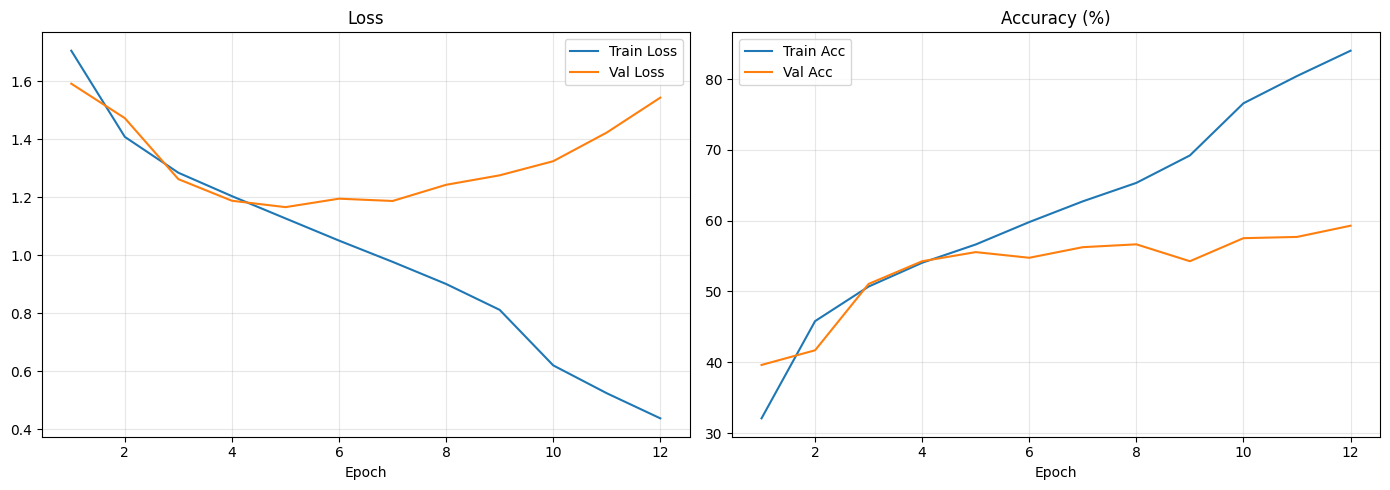

In [25]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"],   label="Val Loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, [a*100 for a in history["train_acc"]], label="Train Acc")
axes[1].plot(epochs_range, [a*100 for a in history["val_acc"]],   label="Val Acc")
axes[1].set_title("Accuracy (%)"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "training_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

# Model Evaluation on Test Set

In [26]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            outputs = model(images)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {test_acc*100:.2f}%\n")

report_text = classification_report(all_labels, all_preds, target_names=class_names, digits=4)
print(report_text)
report_dict = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)

Test Accuracy: 55.39%

              precision    recall  f1-score   support

       angry     0.3971    0.5438    0.4590       958
     disgust     0.0000    0.0000    0.0000       111
        fear     0.3681    0.1826    0.2441      1024
       happy     0.8001    0.8078    0.8039      1774
     neutral     0.5936    0.4347    0.5019      1233
         sad     0.3877    0.5950    0.4695      1247
    surprise     0.7427    0.6703    0.7046       831

    accuracy                         0.5539      7178
   macro avg     0.4699    0.4620    0.4547      7178
weighted avg     0.5585    0.5539    0.5441      7178



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

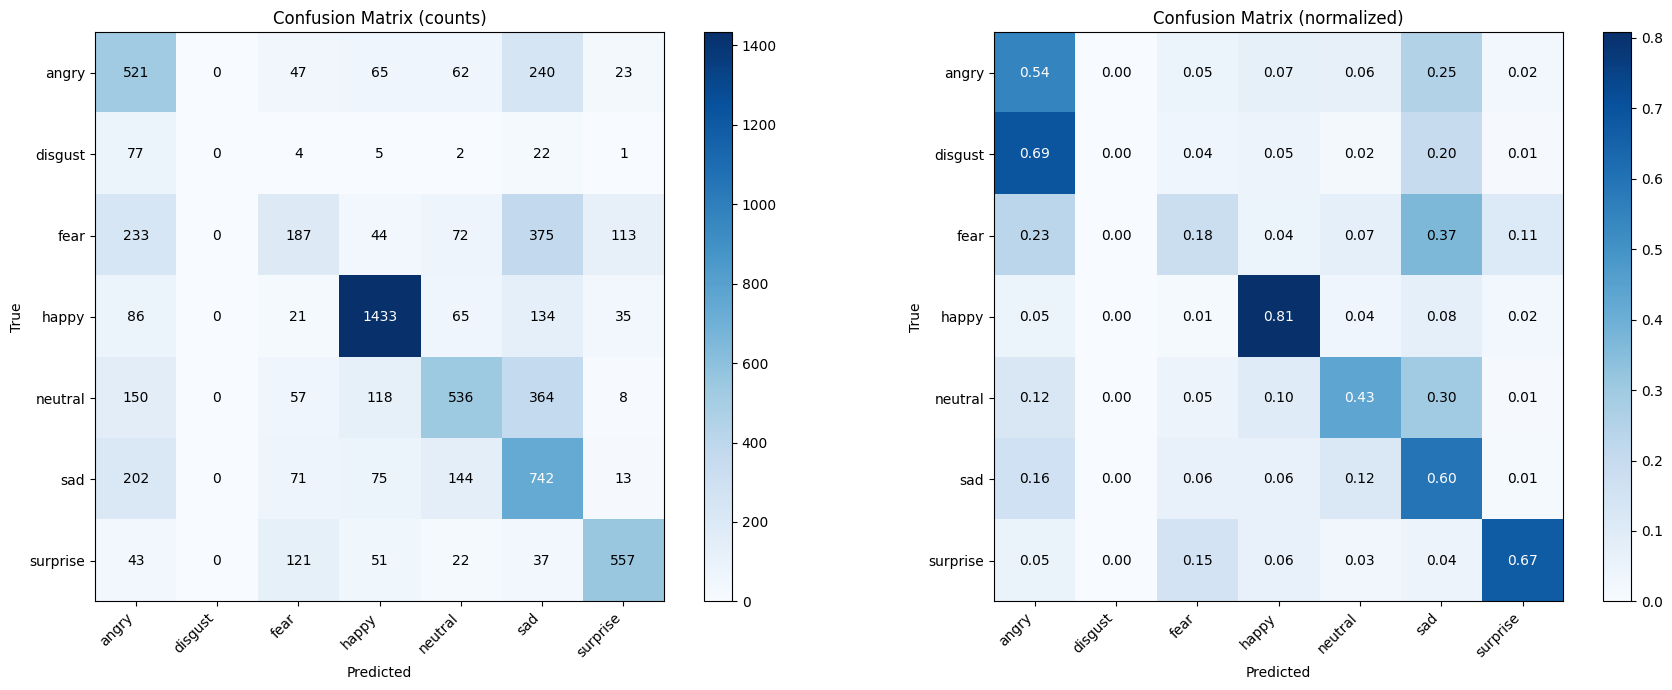

In [27]:
import itertools

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, data, title, fmt in [(axes[0], cm, "Confusion Matrix (counts)", "d"),
                             (axes[1], cm_norm, "Confusion Matrix (normalized)", ".2f")]:
    im = ax.imshow(data, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    thresh = data.max() / 2
    for i, j in itertools.product(range(data.shape[0]), range(data.shape[1])):
        ax.text(j, i, format(data[i, j], fmt), ha="center", va="center",
                color="white" if data[i, j] > thresh else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

# Save Trained Model & Artifacts

In [28]:
# 1) Final model weights (state_dict) - best validation checkpoint
torch.save(model.state_dict(), os.path.join(SAVE_DIR, "facial_emotion_model.pth"))

# 2) Full checkpoint (for resuming / reproducing)
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "num_classes": num_classes,
    "class_to_idx": full_train_dataset.class_to_idx,
    "best_val_loss": best_val_loss,
    "best_val_acc": best_val_acc,
    "test_acc": test_acc,
    "epochs_trained": len(history["train_loss"]),
}, os.path.join(SAVE_DIR, "facial_emotion_checkpoint.pth"))

# 3) Whole model object (TorchScript) - loads without needing the class definition
model.eval()
scripted = torch.jit.trace(model, torch.randn(1, 1, 48, 48).to(device))
scripted.save(os.path.join(SAVE_DIR, "facial_emotion_model_scripted.pt"))

# 4) Class mapping, history, metrics, report
with open(os.path.join(SAVE_DIR, "class_to_idx.json"), "w") as f:
    json.dump(full_train_dataset.class_to_idx, f, indent=2)

with open(os.path.join(SAVE_DIR, "training_history.json"), "w") as f:
    json.dump(history, f, indent=2)

with open(os.path.join(SAVE_DIR, "metrics.json"), "w") as f:
    json.dump({"test_accuracy": float(test_acc),
               "best_val_loss": float(best_val_loss),
               "best_val_accuracy": float(best_val_acc),
               "classification_report": report_dict}, f, indent=2)

with open(os.path.join(SAVE_DIR, "classification_report.txt"), "w") as f:
    f.write(report_text)

# 5) Copy the sample-images plot saved earlier (if it exists)
sample_png = "/content/final_visualizing_sample_images.png"
if os.path.exists(sample_png):
    shutil.copy(sample_png, SAVE_DIR)

print("Saved files:")
for fn in sorted(os.listdir(SAVE_DIR)):
    print(f" - {fn}  ({os.path.getsize(os.path.join(SAVE_DIR, fn))/1024:.1f} KB)")

Saved files:
 - class_to_idx.json  (0.1 KB)
 - classification_report.txt  (0.6 KB)
 - confusion_matrix.png  (231.1 KB)
 - facial_emotion_checkpoint.pth  (18461.1 KB)
 - facial_emotion_model.pth  (6157.3 KB)
 - facial_emotion_model_best.pth  (6157.5 KB)
 - facial_emotion_model_scripted.pt  (6182.3 KB)
 - final_visualizing_sample_images.png  (129.7 KB)
 - metrics.json  (1.5 KB)
 - training_curves.png  (128.5 KB)
 - training_history.json  (1.4 KB)


# Inference / Prediction

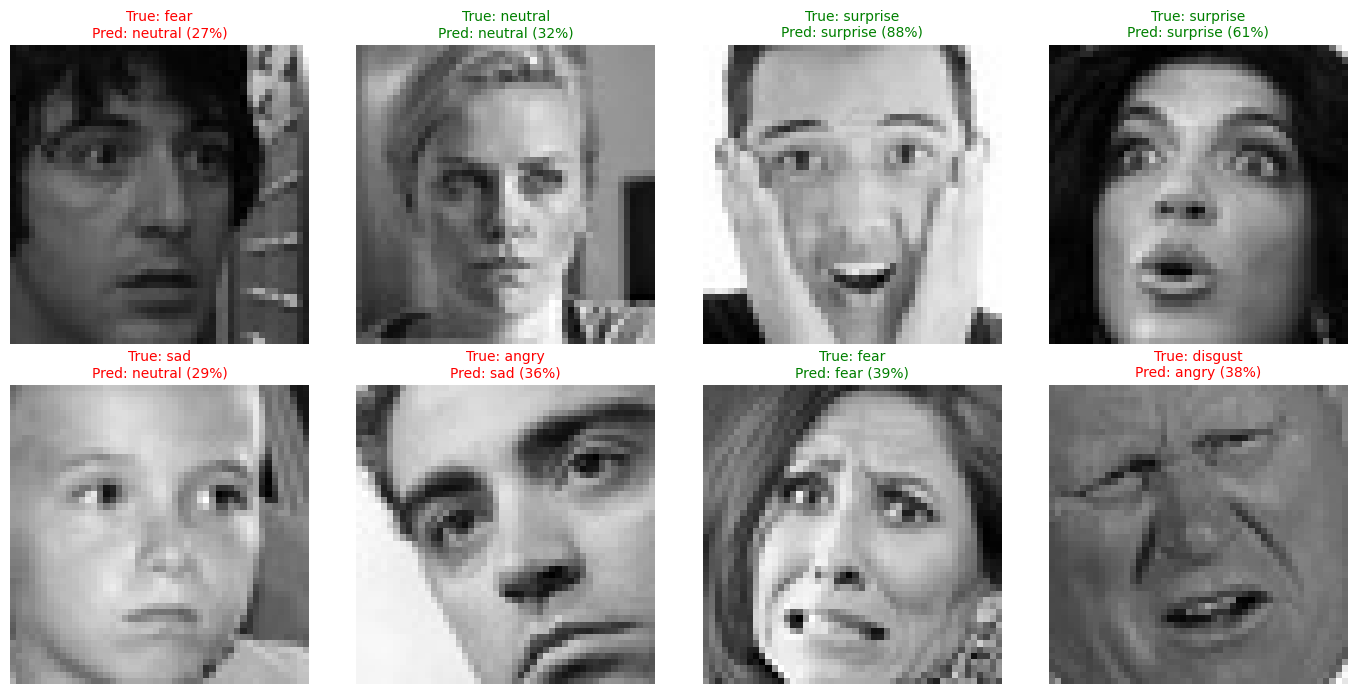

In [29]:
from PIL import Image
from torchvision import transforms

idx_to_class = {v: k for k, v in full_train_dataset.class_to_idx.items()}

infer_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor()
])

def predict_emotion(image_path, model=model, top_k=3):
    img = Image.open(image_path).convert("L")
    x = infer_transform(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0].cpu().numpy()
    top = probs.argsort()[::-1][:top_k]
    return [(idx_to_class[i], float(probs[i])) for i in top], img

# Demo: predict a few random test images
import random
random.seed(1)
samples = random.sample(range(len(test_dataset)), 8)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flatten(), samples):
    path_i, true_label = test_dataset.samples[i]
    preds, img = predict_emotion(path_i)
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ok = preds[0][0] == idx_to_class[true_label]
    ax.set_title(f"True: {idx_to_class[true_label]}\nPred: {preds[0][0]} ({preds[0][1]*100:.0f}%)",
                 color="green" if ok else "red", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "sample_predictions.png"), dpi=200, bbox_inches="tight")
plt.show()

# Zip All Models & Download

In [30]:
# Zip everything inside SAVE_DIR (models + json + plots + reports)
zip_base = "/content/facial_emotion_models"
zip_path = shutil.make_archive(zip_base, "zip", SAVE_DIR)
print("Zip created:", zip_path, f"({os.path.getsize(zip_path)/1024/1024:.2f} MB)")

# Backup copy to Google Drive (Drive is already mounted above)
try:
    drive_dir = "/content/drive/MyDrive/face recogination"
    os.makedirs(drive_dir, exist_ok=True)
    shutil.copy(zip_path, drive_dir)
    print("Backup copied to Drive:", drive_dir)
except Exception as e:
    print("Drive backup skipped:", e)

# Download to your computer
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Auto-download failed, download manually from the Files panel:", zip_path, "|", e)

Zip created: /content/facial_emotion_models.zip (29.40 MB)
Backup copied to Drive: /content/drive/MyDrive/face recogination


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>